# Figure S1: JUMP Map Cross-Source Reproducibility

Examines reproducibility of the JUMP phenotypic map across data sources at the source, perturbation, and target-prediction levels.

This notebook generates:
1. Pairwise source reproducibility KS statistic clustermap
2. Pairwise perturbation reproducibility KS statistic clustermap
3. Pairwise target prediction mAP clustermap
4. Recall by source plot

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
from typing import List, Optional

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import kneighbors_graph

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

from phenocompass.evaluation.map_evaluation import reproducibility_ks

%matplotlib inline

# --- Base directories ---
BASE_DIR = str(REPO_ROOT)

# --- Matplotlib configuration ---
setup_publication_style(BASE_DIR)

# --- Output directories ---
DATA_DIR = os.path.join(BASE_DIR, "data", "cross_source_reproducibility")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "jump_phenotypic_map")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# --- Final data directory ---
FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

# --- Control flag ---
FORCE_RECOMPUTE = False

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'haiku'
Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Helper Functions

In [2]:
def generate_consensus_profiles(df, feature_cols, metadata_cols):
    """Mean-aggregate well-level profiles to consensus per JCP2022 compound."""
    df_group = df.groupby('Metadata_JCP2022', as_index=False)
    d1 = dict.fromkeys(feature_cols, 'mean')
    d2 = dict.fromkeys(metadata_cols, 'first')
    df_agg = df_group.agg({**d1, **d2})
    return df_agg


def KNN_mAP(
    df, feature_names, class_type, k=20, metric="cosine",
    use_float16=False, data_loader_check=False,
):
    """Compute mean average precision via kNN graph on feature embeddings."""
    labels = pd.factorize(df[class_type])[0].astype(np.int16)

    centroids = df[feature_names].values
    if use_float16:
        centroids = centroids.astype(np.float16)
    X = np.asarray(centroids)

    csr_mat = kneighbors_graph(
        X, k, mode="distance", include_self=True, metric=metric,
    )

    indice_mat = csr_mat.indices.reshape([-1, k])
    retrieved_neighbors = np.take(labels, indice_mat, axis=0)

    preds = retrieved_neighbors[:, 1:] == retrieved_neighbors[:, 0][:, np.newaxis]
    tp = np.cumsum(preds, axis=1)
    num_pos = tp[:, -1]
    k_range = np.arange(1, preds.shape[1] + 1)
    pr_k = tp / k_range

    if data_loader_check:
        num_pos = 1
        ap = (pr_k * preds).sum(axis=1) / num_pos
    else:
        indices = num_pos > 0
        ap = (pr_k[indices] * preds[indices]).sum(axis=1) / num_pos[indices]
    return ap, retrieved_neighbors, df[class_type].nunique(), num_pos


def target_prediction(df_matched, df_well_test, feature_cols):
    """Compute mAP for target prediction using consensus profiles."""
    metadata_cols = [name for name in df_well_test.columns if name.startswith('Metadata')]
    df_consensus = generate_consensus_profiles(df_well_test, feature_cols, metadata_cols)
    df_eval = df_matched

    tmp = df_eval[['target', 'pert_iname']].groupby('target').count()
    sel_targets = tmp[tmp['pert_iname'] >= 2].index
    df_eval_clean = df_eval[df_eval['target'].isin(sel_targets)]

    df_eval_consensus = df_eval_clean.merge(df_consensus, on='Metadata_JCP2022', how='inner')

    n_samples = df_eval_consensus.shape[0]
    ap, retrieved_neighbors, _, num_pos = KNN_mAP(
        df_eval_consensus, feature_cols, 'target',
        k=n_samples, metric='cosine', use_float16=False,
    )

    return np.mean(ap)

## 3. Load Dataset

In [3]:
def read_target2_metadata():
    """Load and merge JUMP Target2 compound annotations with target labels."""
    compound_csv = os.path.join(FINAL_DATA_DIR, "compound_annotations", "jump_compound_catalog.csv.gz")
    target2_csv = os.path.join(FINAL_DATA_DIR, "compound_annotations", "jump_target2_annotations.csv")

    target_cols = [
        "InChIKey", "target", "pert_iname", "pert_type",
        "control_type", "Target_Association_Class", "Incorrect Target",
    ]

    df_compound = pd.read_csv(compound_csv, compression="gzip").dropna(
        subset=["Metadata_InChIKey"]
    )
    df_target2 = pd.read_csv(target2_csv, usecols=target_cols).dropna(subset=["InChIKey"])

    df_target2 = df_target2[
        (df_target2["Incorrect Target"] != "Y")
        & (df_target2["Target_Association_Class"].isin(["A", "B", "C"]))
    ].copy()

    df_compound["InChIKey_first"] = df_compound["Metadata_InChIKey"].str.split("-").str[0]
    df_target2["InChIKey_first"] = df_target2["InChIKey"].str.split("-").str[0]

    exact = df_target2.merge(
        df_compound, left_on="InChIKey", right_on="Metadata_InChIKey", how="left",
    )

    matched_exact = exact.dropna(subset=["Metadata_JCP2022"])
    unmatched = exact[exact["Metadata_JCP2022"].isna()]

    fallback_input = unmatched[
        list(df_target2.columns.drop('InChIKey_first')) + ['InChIKey_first_x']
    ].rename(columns={'InChIKey_first_x': 'InChIKey_first'})

    fallback = fallback_input.merge(df_compound, on='InChIKey_first', how='left')

    matched_fallback = fallback.dropna(subset=["Metadata_JCP2022"])
    unmatched_final = fallback[fallback["Metadata_JCP2022"].isna()][df_target2.columns]

    df_matched = pd.concat([matched_exact, matched_fallback], ignore_index=True)
    return df_matched, unmatched_final


def read_cell_profiler(source_names):
    """Load CellProfiler features for TARGET2 plates filtered to given sources."""
    cell_profiler_path = os.path.join(
        FINAL_DATA_DIR, "jump_map", "jump_mapv1_20231220_pc384_sphere_center.parquet"
    )
    df = pd.read_parquet(cell_profiler_path)
    df = df[df['Metadata_PlateType'] == 'TARGET2']
    df_well = df[df['Metadata_Source'].isin(source_names)]
    feature_cols = [name for name in df_well.columns if 'Metadata' not in name]
    return df_well, feature_cols


df_matched, df_unmatched = read_target2_metadata()
print("Matched compounds")
print("Unmatched compounds")

source_list = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13]
source_names = [f'source_{source}' for source in source_list]
num_sources = len(source_list)
df_well, feature_cols = read_cell_profiler(source_names)
print("Well-level profiles")
print("Feature columns")

Matched compounds
Unmatched compounds
Well-level profiles
Feature columns


## 4. Pairwise KS on Source

In [4]:
cache_path = os.path.join(DATA_DIR, "source_ks.parquet")
if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    df_source_ks = pd.read_parquet(cache_path)
    print("Loaded cached")
else:
    ks_arr = np.zeros([num_sources, num_sources])
    source_key = 'Metadata_Source'
    for i in range(num_sources):
        for j in range(i, num_sources):
            if i == j:
                df_well_subset = df_well[df_well[source_key] == source_names[i]]
            else:
                df_well_subset = df_well[
                    df_well[source_key].isin([source_names[i], source_names[j]])
                ]

            ks_df = reproducibility_ks(
                df_well_subset, variables=[source_key], columns=feature_cols
            )
            ks_arr[i, j] = ks_df.iloc[0]["statistic"]
            ks_arr[j, i] = ks_df.iloc[0]["statistic"]

    df_source_ks = pd.DataFrame(ks_arr, columns=source_names, index=source_names)
    df_source_ks.to_parquet(cache_path)
    print("Cached to")

df_source_ks.head()

Loaded cached


,source_2,source_3,source_4,source_5,source_6,source_7,source_8,source_9,source_10,source_11,source_13
source_2,0.0095,0.0480,0.0496,0.0390,0.0385,0.0930,0.0724,0.0644,0.0642,0.0844,0.0898
source_3,0.0480,0.0079,0.0465,0.0726,0.0581,0.0941,0.0779,0.0624,0.0601,0.0681,0.0826
source_4,0.0496,0.0465,0.0094,0.0596,0.0573,0.0905,0.0692,0.0610,0.0554,0.0722,0.0881
source_5,0.0390,0.0726,0.0596,0.0174,0.0494,0.0834,0.0712,0.0607,0.0612,0.0683,0.0915
source_6,0.0385,0.0581,0.0573,0.0494,0.0180,0.0837,0.0616,0.0593,0.0530,0.0752,0.0829


Figure already exists


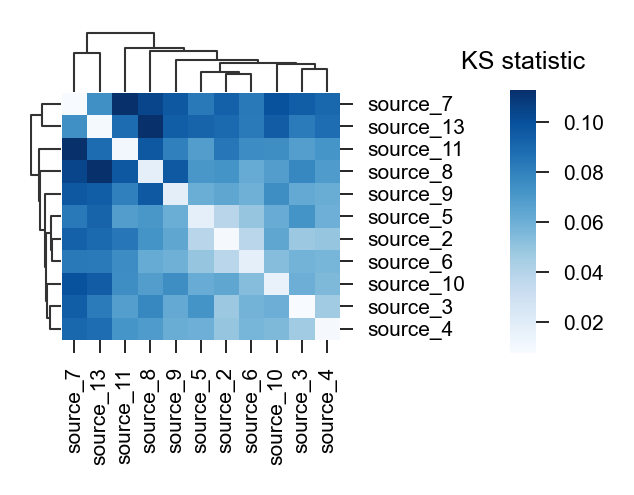

Figure data already exists


In [5]:
fig_path = os.path.join(FIGURE_DIR, "FigS1_source_ks_clustermap.pdf")
g = sns.clustermap(
    df_source_ks,
    figsize=(1.75, 1.75),
    row_cluster=True,
    dendrogram_ratio=(.1, .2),
    cbar_pos=(1, 0.3, 0.05, 0.5),
    cmap='Blues',
)
g.cax.set_title("KS statistic", pad=5)  # Label the colorbar

save_figure(fig_path, force_recompute=FORCE_RECOMPUTE, fig=g.fig, show=True)

save_figure_data(
    df_source_ks,
    os.path.join(FIGURE_DIR, "FigS1_source_ks_data.tsv"),
    force_recompute=FORCE_RECOMPUTE,
    index=True,
)

## 5. Pairwise KS on Perturbation

In [6]:
cache_path = os.path.join(DATA_DIR, "perturbation_ks.parquet")
if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    df_pert_ks = pd.read_parquet(cache_path)
    print("Loaded cached")
else:
    ks_arr = np.zeros([num_sources, num_sources])
    source_key = 'Metadata_Source'
    ks_key = 'Metadata_Perturbation'
    for i in range(num_sources):
        for j in range(i, num_sources):
            if i == j:
                df_well_subset = df_well[df_well[source_key] == source_names[i]]
            else:
                df_well_subset = df_well[
                    df_well[source_key].isin([source_names[i], source_names[j]])
                ]

            ks_df = reproducibility_ks(
                df_well_subset, variables=[ks_key], columns=feature_cols
            )
            ks_arr[i, j] = ks_df.iloc[0]["statistic"]
            ks_arr[j, i] = ks_df.iloc[0]["statistic"]

    df_pert_ks = pd.DataFrame(ks_arr, columns=source_names, index=source_names)
    df_pert_ks.to_parquet(cache_path)
    print("Cached to")

df_pert_ks.head()

Loaded cached


,source_2,source_3,source_4,source_5,source_6,source_7,source_8,source_9,source_10,source_11,source_13
source_2,0.5610,0.4221,0.4398,0.4884,0.5059,0.4142,0.4719,0.0939,0.4209,0.4029,0.3657
source_3,0.4221,0.4796,0.4335,0.4128,0.4252,0.4030,0.4446,0.1983,0.4070,0.4176,0.3838
source_4,0.4398,0.4335,0.5331,0.4005,0.4293,0.4499,0.4706,0.2104,0.4436,0.4364,0.4312
source_5,0.4884,0.4128,0.4005,0.5540,0.4745,0.4399,0.4976,0.2360,0.4658,0.4496,0.4372
source_6,0.5059,0.4252,0.4293,0.4745,0.5697,0.4517,0.5224,0.2158,0.4836,0.4561,0.4510


Figure already exists


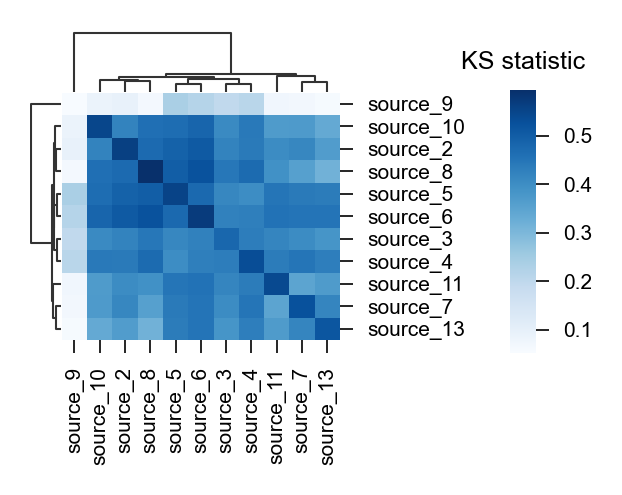

Figure data already exists


In [7]:
fig_path = os.path.join(FIGURE_DIR, "FigS1_perturbation_ks_clustermap.pdf")
g = sns.clustermap(
    df_pert_ks,
    figsize=(1.75, 1.75),
    row_cluster=True,
    dendrogram_ratio=(.1, .2),
    cbar_pos=(1, 0.3, 0.05, 0.5),
    cmap='Blues',
)
g.cax.set_title("KS statistic", pad=5)
save_figure(fig_path, force_recompute=FORCE_RECOMPUTE, fig=g.fig, show=True)

save_figure_data(
    df_pert_ks,
    os.path.join(FIGURE_DIR, "FigS1_perturbation_ks_data.tsv"),
    force_recompute=FORCE_RECOMPUTE,
    index=True,
)

## 6. Pairwise mAP on Target Prediction

In [8]:
cache_path = os.path.join(DATA_DIR, "target_mAP.parquet")
if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    df_target_mAP = pd.read_parquet(cache_path)
    print("Loaded cached")
else:
    df_well_reload, feature_cols_reload = read_cell_profiler(source_names)

    mAP_arr = np.zeros([num_sources, num_sources])
    source_key = 'Metadata_Source'
    for i in range(num_sources):
        for j in range(i, num_sources):
            if i == j:
                df_well_subset = df_well_reload[
                    df_well_reload[source_key] == source_names[i]
                ]
            else:
                df_well_subset = df_well_reload[
                    df_well_reload[source_key].isin([source_names[i], source_names[j]])
                ]

            mAP = target_prediction(df_matched, df_well_subset, feature_cols_reload)
            mAP_arr[i, j] = mAP
            mAP_arr[j, i] = mAP

    df_target_mAP = pd.DataFrame(mAP_arr, columns=source_names, index=source_names)
    df_target_mAP.to_parquet(cache_path)
    print("Cached to")

df_target_mAP.head()

Loaded cached


,source_2,source_3,source_4,source_5,source_6,source_7,source_8,source_9,source_10,source_11,source_13
source_2,0.196478,0.190244,0.164663,0.190948,0.206556,0.172141,0.191332,0.174799,0.176227,0.216436,0.171158
source_3,0.190244,0.173958,0.165595,0.195897,0.186317,0.176069,0.174075,0.183669,0.174459,0.195069,0.181096
source_4,0.164663,0.165595,0.140590,0.183126,0.186597,0.138603,0.141975,0.135661,0.143712,0.162309,0.130037
source_5,0.190948,0.195897,0.183126,0.199540,0.203457,0.181882,0.187643,0.193692,0.195777,0.200771,0.195602
source_6,0.206556,0.186317,0.186597,0.203457,0.182265,0.181500,0.194121,0.173445,0.186687,0.204362,0.186731


Figure already exists


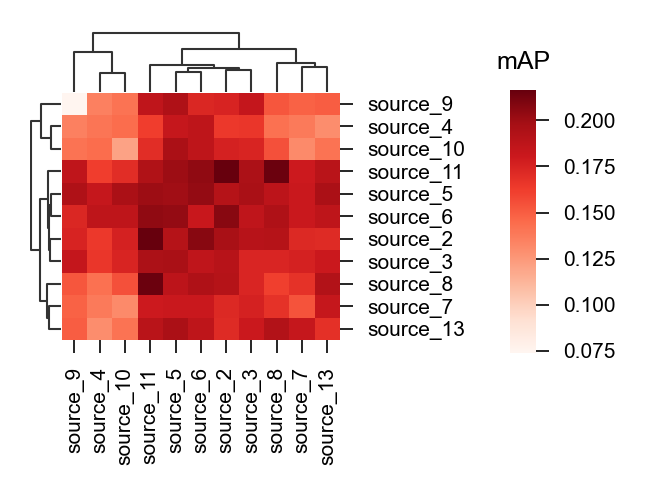

Figure data already exists


In [9]:
fig_path = os.path.join(FIGURE_DIR, "FigS1_target_mAP_clustermap.pdf")
g = sns.clustermap(
    df_target_mAP,
    figsize=(1.75, 1.75),
    row_cluster=True,
    dendrogram_ratio=(.1, .2),
    cbar_pos=(1, 0.3, 0.05, 0.5),
    cmap='Reds',
)
g.cax.set_title("mAP", pad=5)
save_figure(fig_path, force_recompute=FORCE_RECOMPUTE, fig=g.fig, show=True)

save_figure_data(
    df_target_mAP,
    os.path.join(FIGURE_DIR, "FigS1_target_mAP_data.tsv"),
    force_recompute=FORCE_RECOMPUTE,
    index=True,
)

## 7. Recall for Different Source Subsets

Figure already exists


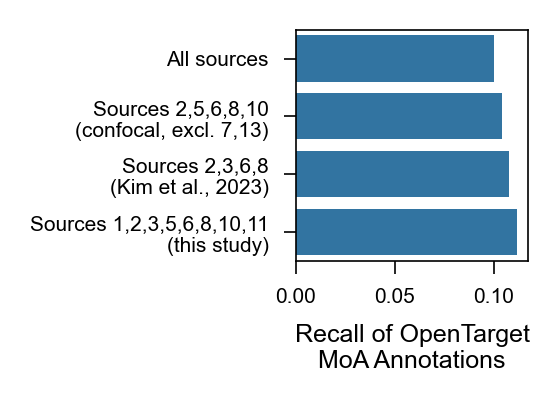

In [10]:
recall_sources_df = pd.read_csv(os.path.join(FIGURE_DIR, "FigS1_recall_sources.tsv"), sep="\t")
plt.figure(figsize=(1., 1.))
ax = sns.barplot(x="value", y="map", data=recall_sources_df)
plt.xlabel("Recall of OpenTarget\nMoA Annotations")
plt.ylabel("")

# Update the y axis ticks such that there's a new line after the second space
def insert_newline_after_second_space(label):
    parts = label.split(" ")
    if len(parts) <= 2:
        return label
    return " ".join(parts[:2]) + "\n" + " ".join(parts[2:])

# Get current yticklabels, update and set
yticklabels = [item.get_text() for item in ax.get_yticklabels()]
new_labels = [insert_newline_after_second_space(label) for label in yticklabels]
ax.set_yticklabels(new_labels)

save_figure(os.path.join(FIGURE_DIR, "FigS1_recall_sources.pdf"), force_recompute=FORCE_RECOMPUTE, fig=plt.gcf(), show=True)
plt.show()